# ECE 3715 Mini-Project 1


In [1]:
%pip install numpy scipy matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\minpy\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
from itertools import product
import mp1lib

# Master Seed
SEED = 1 
rng = np.random.default_rng(SEED)

# Spawn generators for your partner's steps
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_bonus = rng.spawn(1)[0]

print("Kernel initialized and seeded.")

Kernel initialized and seeded.


## Hand-checkable test for `bsc`

For $p=0$, no bits should flip, so the output should match the input exactly.


In [3]:
test_bits = np.array([0, 1, 0, 1])
test_output = mp1lib.bsc(test_bits, 0.0, rng_step1)

print("Input: ", test_bits)
print("Output:", test_output)

assert np.array_equal(test_bits, test_output)
print("bsc test passed.")


Input:  [0 1 0 1]
Output: [0 1 0 1]
bsc test passed.


# Step 1: The Sample Space and the Axioms

For this step, the packet has 4 bits and $p=0.1$.

- $A$: at least one error in the first two bits
- $B$: exactly two errors in the packet
- $C$: the fourth bit is in error

For a pattern with $k$ errors,

$$
P(\text{pattern})=p^k(1-p)^{4-k}.
$$


In [4]:
p = 0.1
patterns = list(product([0, 1], repeat=4))
pattern_probabilities = []

for pattern in patterns:
    k = sum(pattern)
    probability = (p**k) * ((1-p)**(4-k))
    pattern_probabilities.append(probability)

exact_pattern_table = pd.DataFrame({
    "Pattern": ["".join(map(str, pattern)) for pattern in patterns],
    "Exact Probability": pattern_probabilities
})

print(exact_pattern_table.to_string(index=False))
print()
print("Sum of all exact probabilities: %.12f" % sum(pattern_probabilities))


Pattern  Exact Probability
   0000             0.6561
   0001             0.0729
   0010             0.0729
   0011             0.0081
   0100             0.0729
   0101             0.0081
   0110             0.0081
   0111             0.0009
   1000             0.0729
   1001             0.0081
   1010             0.0081
   1011             0.0009
   1100             0.0081
   1101             0.0009
   1110             0.0009
   1111             0.0001

Sum of all exact probabilities: 1.000000000000


### Exact probabilities for $A$, $B$, and $C$

For $A$, using the complement is easier:

$$
P(A)=1-P(\text{no errors in the first two bits})
$$

$$
P(A)=1-(0.9)^2=0.19
$$

For $B$, exactly 2 of the 4 bits must be in error:

$$
P(B)=\binom{4}{2}(0.1)^2(0.9)^2
$$

$$
P(B)=6(0.01)(0.81)=0.0486
$$

For $C$, the fourth bit has error probability $0.1$:

$$
P(C)=0.1
$$


In [5]:
exact_A = 0.0
exact_B = 0.0
exact_C = 0.0
exact_AB = 0.0
exact_AC = 0.0
exact_BC = 0.0
exact_ABC = 0.0
exact_union_direct = 0.0

for pattern, probability in zip(patterns, pattern_probabilities):
    A_exact = (pattern[0] == 1 or pattern[1] == 1)
    B_exact = (sum(pattern) == 2)
    C_exact = (pattern[3] == 1)

    if A_exact:
        exact_A += probability
    if B_exact:
        exact_B += probability
    if C_exact:
        exact_C += probability
    if A_exact and B_exact:
        exact_AB += probability
    if A_exact and C_exact:
        exact_AC += probability
    if B_exact and C_exact:
        exact_BC += probability
    if A_exact and B_exact and C_exact:
        exact_ABC += probability
    if A_exact or B_exact or C_exact:
        exact_union_direct += probability

print("Exact P(A) = %.4f" % exact_A)
print("Exact P(B) = %.4f" % exact_B)
print("Exact P(C) = %.4f" % exact_C)


Exact P(A) = 0.1900
Exact P(B) = 0.0486
Exact P(C) = 0.1000


In [6]:
# Monte Carlo with N = 10^6 packets
N1 = 10**6

sent_bits = np.zeros((N1, 4), dtype=np.int8)
received_bits = mp1lib.bsc(sent_bits, p, rng_step1)

A = (received_bits[:, 0] == 1) | (received_bits[:, 1] == 1)
B = (np.sum(received_bits, axis=1) == 2)
C = (received_bits[:, 3] == 1)

emp_A = np.mean(A)
emp_B = np.mean(B)
emp_C = np.mean(C)
emp_AB = np.mean(A & B)
emp_AC = np.mean(A & C)
emp_BC = np.mean(B & C)
emp_ABC = np.mean(A & B & C)

print("Empirical P(A) = %.6f" % emp_A)
print("Empirical P(B) = %.6f" % emp_B)
print("Empirical P(C) = %.6f" % emp_C)


Empirical P(A) = 0.190599
Empirical P(B) = 0.048737
Empirical P(C) = 0.100071


### Inclusion-exclusion

For three events,

$$
P(A\cup B\cup C)
=
P(A)+P(B)+P(C)
-P(A\cap B)-P(A\cap C)-P(B\cap C)
+P(A\cap B\cap C).
$$

The union is also calculated directly from the sample space and from the simulation to check that the results match.


In [7]:
exact_union_formula = (
    exact_A + exact_B + exact_C
    - exact_AB - exact_AC - exact_BC
    + exact_ABC
)

emp_union_formula = (
    emp_A + emp_B + emp_C
    - emp_AB - emp_AC - emp_BC
    + emp_ABC
)

emp_union_direct = np.mean(A | B | C)

print("Exact union from formula: %.6f" % exact_union_formula)
print("Exact union directly:     %.6f" % exact_union_direct)
print("Exact formula-direct difference: %.3e" %
      abs(exact_union_formula - exact_union_direct))
print()
print("Empirical union from formula: %.6f" % emp_union_formula)
print("Empirical union directly:     %.6f" % emp_union_direct)
print("Empirical formula-direct difference: %.3e" %
      abs(emp_union_formula - emp_union_direct))


Exact union from formula: 0.271000
Exact union directly:     0.271000
Exact formula-direct difference: 0.000e+00

Empirical union from formula: 0.271552
Empirical union directly:     0.271552
Empirical formula-direct difference: 0.000e+00


### Standard error

For a probability estimate from $N$ independent trials,

$$
SE(\hat p)=\sqrt{\frac{p(1-p)}{N}}.
$$

Here $N=10^6$. Each empirical result is checked to see whether it is within three standard errors of the exact value.


In [8]:
event_names = [
    "P(A)",
    "P(B)",
    "P(C)",
    "P(A and B)",
    "P(A and C)",
    "P(B and C)",
    "P(A and B and C)"
]

exact_values = np.array([
    exact_A, exact_B, exact_C,
    exact_AB, exact_AC, exact_BC, exact_ABC
])

empirical_values = np.array([
    emp_A, emp_B, emp_C,
    emp_AB, emp_AC, emp_BC, emp_ABC
])

differences = np.abs(empirical_values - exact_values)
standard_errors = np.sqrt(exact_values * (1 - exact_values) / N1)

step1_table = pd.DataFrame({
    "Event": event_names,
    "Exact": exact_values,
    "Empirical": empirical_values,
    "Difference": differences,
    "Standard Error": standard_errors,
    "Within 3 SE": differences <= 3 * standard_errors
})

print(step1_table.to_string(index=False))

union_difference = abs(emp_union_direct - exact_union_direct)
union_se = np.sqrt(exact_union_direct * (1 - exact_union_direct) / N1)

print()
print("Union exact: %.6f" % exact_union_direct)
print("Union empirical: %.6f" % emp_union_direct)
print("Union difference: %.6f" % union_difference)
print("Union standard error: %.6f" % union_se)
print("Union within 3 SE:", union_difference <= 3 * union_se)


           Event  Exact  Empirical  Difference  Standard Error  Within 3 SE
            P(A) 0.1900   0.190599    0.000599        0.000392         True
            P(B) 0.0486   0.048737    0.000137        0.000215         True
            P(C) 0.1000   0.100071    0.000071        0.000300         True
      P(A and B) 0.0405   0.040620    0.000120        0.000197         True
      P(A and C) 0.0190   0.019118    0.000118        0.000137         True
      P(B and C) 0.0243   0.024430    0.000130        0.000154         True
P(A and B and C) 0.0162   0.016313    0.000113        0.000126         True

Union exact: 0.271000
Union empirical: 0.271552
Union difference: 0.000552
Union standard error: 0.000444
Union within 3 SE: True


In [9]:
pattern_index = received_bits.dot(
    1 << np.arange(3, -1, -1)
)

counts = np.bincount(
    pattern_index,
    minlength=16
)

empirical_pattern_probabilities = counts / N1
pattern_exact = np.array(pattern_probabilities)

pattern_difference = np.abs(
    empirical_pattern_probabilities - pattern_exact
)

pattern_se = np.sqrt(
    pattern_exact * (1 - pattern_exact) / N1
)

pattern_comparison = pd.DataFrame({
    "Pattern": [
        "".join(map(str, pattern))
        for pattern in patterns
    ],
    "Exact": pattern_exact,
    "Monte Carlo": empirical_pattern_probabilities,
    "Difference": pattern_difference,
    "Standard Error": pattern_se,
    "Within 3 SE": pattern_difference <= 3 * pattern_se
})

print(pattern_comparison.to_string(index=False))


Pattern  Exact  Monte Carlo  Difference  Standard Error  Within 3 SE
   0000 0.6561     0.655609    0.000491        0.000475         True
   0001 0.0729     0.072836    0.000064        0.000260         True
   0010 0.0729     0.072839    0.000061        0.000260         True
   0011 0.0081     0.008117    0.000017        0.000090         True
   0100 0.0729     0.073286    0.000386        0.000260         True
   0101 0.0081     0.008068    0.000032        0.000090         True
   0110 0.0081     0.008150    0.000050        0.000090         True
   0111 0.0009     0.000908    0.000008        0.000030         True
   1000 0.0729     0.072996    0.000096        0.000260         True
   1001 0.0081     0.008245    0.000145        0.000090         True
   1010 0.0081     0.008104    0.000004        0.000090         True
   1011 0.0009     0.000897    0.000003        0.000030         True
   1100 0.0081     0.008053    0.000047        0.000090         True
   1101 0.0009     0.000902    0.0

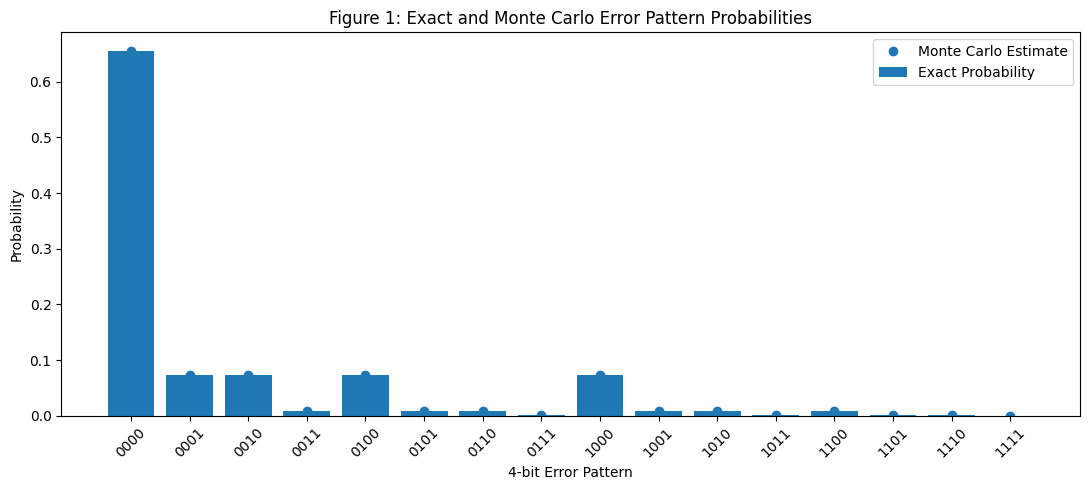

In [10]:
# Figure 1
x = np.arange(16)
labels = ["".join(map(str, pattern)) for pattern in patterns]

plt.figure(figsize=(11, 5))
plt.bar(x, pattern_probabilities, label="Exact Probability")
plt.plot(x, empirical_pattern_probabilities, "o", label="Monte Carlo Estimate")
plt.xticks(x, labels, rotation=45)
plt.xlabel("4-bit Error Pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo Error Pattern Probabilities")
plt.legend()
plt.tight_layout()
plt.show()


### Figure 1 interpretation

The Monte Carlo points are very close to the exact probabilities. The `0000` pattern has the highest probability because none of the four bits have an error. The tables above show the differences and standard errors for comparison with the exact results.


# Step 2: Conditional Probability and Bayes

Let $E$ mean the bit is actually in error and $F$ mean the circuit raises a flag.

$$
P(F|E)=0.95,\qquad P(F|E^c)=0.02,\qquad P(E)=p.
$$

Using total probability,

$$
P(F)=P(F|E)P(E)+P(F|E^c)P(E^c)
$$

$$
P(F)=0.95p+0.02(1-p).
$$

Using Bayes' rule,

$$
P(E|F)
=
\frac{P(F|E)P(E)}{P(F)}
$$

$$
P(E|F)
=
\frac{0.95p}{0.95p+0.02(1-p)}.
$$


In [11]:
def posterior(p):
    return (0.95 * p) / ((0.95 * p) + (0.02 * (1 - p)))

for p_value in [0.1, 0.01, 0.001]:
    print("p = %.4g, posterior = %.6f" %
          (p_value, posterior(p_value)))


p = 0.1, posterior = 0.840708
p = 0.01, posterior = 0.324232
p = 0.001, posterior = 0.045389


### Crossover where the posterior is 0.5

Set

$$
\frac{0.95p}{0.95p+0.02(1-p)}=0.5.
$$

Then

$$
0.95p=0.5[0.95p+0.02(1-p)]
$$

$$
0.95p=0.475p+0.01-0.01p
$$

$$
0.485p=0.01
$$

$$
p=\frac{0.01}{0.485}=0.0206
$$

to three significant figures.


In [12]:
p_cross = 0.01 / 0.485
print("Crossover p = %.3g" % p_cross)

# Monte Carlo verification with N = 10^7 bits
N2 = 10**7

errors = rng_step2.random(N2) < p_cross
flag_draws = rng_step2.random(N2)
flags = np.where(errors, flag_draws < 0.95, flag_draws < 0.02)

number_flags = np.sum(flags)
flagged_and_error = np.sum(flags & errors)

empirical_posterior = flagged_and_error / number_flags
theoretical_posterior = posterior(p_cross)
posterior_difference = abs(empirical_posterior - theoretical_posterior)

posterior_se = np.sqrt(
    empirical_posterior * (1 - empirical_posterior) / number_flags
)

print("Number of flags:", number_flags)
print("Flagged and actually in error:", flagged_and_error)
print("Empirical posterior: %.6f" % empirical_posterior)
print("Theoretical posterior: %.6f" % theoretical_posterior)
print("Difference: %.6f" % posterior_difference)
print("Standard error: %.6f" % posterior_se)
print("Within 3 SE:", posterior_difference <= 3 * posterior_se)


Crossover p = 0.0206
Number of flags: 392477
Flagged and actually in error: 196765
Empirical posterior: 0.501341
Theoretical posterior: 0.500000
Difference: 0.001341
Standard error: 0.000798
Within 3 SE: True


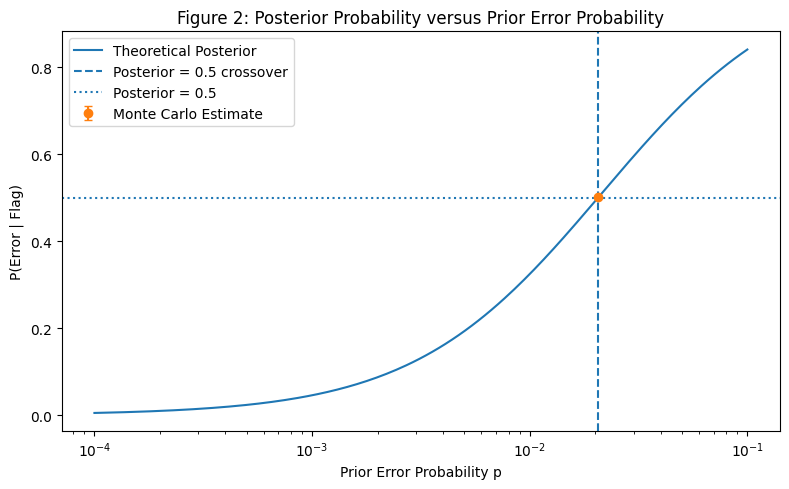

In [13]:
# Figure 2
p_plot = np.logspace(-4, -1, 200)
posterior_plot = posterior(p_plot)

plt.figure(figsize=(8, 5))
plt.plot(p_plot, posterior_plot, label="Theoretical Posterior")
plt.axvline(p_cross, linestyle="--", label="Posterior = 0.5 crossover")
plt.axhline(0.5, linestyle=":", label="Posterior = 0.5")
plt.errorbar(
    p_cross,
    empirical_posterior,
    yerr=posterior_se,
    fmt="o",
    capsize=3,
    label="Monte Carlo Estimate"
)

plt.xscale("log")
plt.xlabel("Prior Error Probability p")
plt.ylabel("P(Error | Flag)")
plt.title("Figure 2: Posterior Probability versus Prior Error Probability")
plt.legend()
plt.tight_layout()
plt.show()


### Figure 2 interpretation

When $p$ is small, the posterior probability is also small even though the circuit detects a real error 95% of the time. The crossover is around $p=0.0206$, where a flagged bit has about a 50% chance of actually being in error. The Monte Carlo result is close to the theoretical value and is within three standard errors.

For a manager, a 95% detection rate does not mean that 95% of the flags are real errors. If the link is already very good, real errors are rare, so the 2% false-positive rate can still make up a large part of the flags.


# Step 3: Independence

For two fair coins:

- $E_1$: the first coin is heads
- $E_2$: the second coin is heads
- $E_3$: the two coins match

Each event has probability $1/2$.

For the three pairs,

$$
P(E_1\cap E_2)=\frac{1}{4}=P(E_1)P(E_2)
$$

$$
P(E_1\cap E_3)=\frac{1}{4}=P(E_1)P(E_3)
$$

$$
P(E_2\cap E_3)=\frac{1}{4}=P(E_2)P(E_3).
$$

The events are therefore pairwise independent.

For all three events,

$$
P(E_1\cap E_2\cap E_3)=\frac{1}{4},
$$

but

$$
P(E_1)P(E_2)P(E_3)=\frac{1}{8}.
$$

Since these are not equal, the three events are not mutually independent.


In [14]:
# Part 1: numerical verification with N = 10^6
N3 = 10**6

coin1 = rng_step3.integers(0, 2, N3)
coin2 = rng_step3.integers(0, 2, N3)

E1 = (coin1 == 1)
E2 = (coin2 == 1)
E3 = (coin1 == coin2)

pE1 = np.mean(E1)
pE2 = np.mean(E2)
pE3 = np.mean(E3)

rows = [
    ("E1 and E2", pE1 * pE2, np.mean(E1 & E2), 0.25),
    ("E1 and E3", pE1 * pE3, np.mean(E1 & E3), 0.25),
    ("E2 and E3", pE2 * pE3, np.mean(E2 & E3), 0.25),
    ("E1 and E2 and E3", pE1 * pE2 * pE3,
     np.mean(E1 & E2 & E3), 0.25)
]

part1_table = []

for name, product_prob, joint_prob, exact_joint in rows:
    difference_from_exact = abs(joint_prob - exact_joint)
    joint_se = np.sqrt(exact_joint * (1 - exact_joint) / N3)

    part1_table.append([
        name,
        product_prob,
        joint_prob,
        exact_joint,
        abs(product_prob - joint_prob),
        difference_from_exact,
        joint_se
    ])

part1_table = pd.DataFrame(
    part1_table,
    columns=[
        "Comparison",
        "Product of Empirical Probabilities",
        "Empirical Joint Probability",
        "Exact Joint Probability",
        "|Product - Joint|",
        "|Empirical Joint - Exact|",
        "Joint Standard Error"
    ]
)

print(part1_table.to_string(index=False))


      Comparison  Product of Empirical Probabilities  Empirical Joint Probability  Exact Joint Probability  |Product - Joint|  |Empirical Joint - Exact|  Joint Standard Error
       E1 and E2                            0.249970                      0.25024                     0.25           0.000270                    0.00024              0.000433
       E1 and E3                            0.250431                      0.25024                     0.25           0.000191                    0.00024              0.000433
       E2 and E3                            0.250079                      0.25024                     0.25           0.000161                    0.00024              0.000433
E1 and E2 and E3                            0.125120                      0.25024                     0.25           0.125120                    0.00024              0.000433


In [15]:
# Part 2: two receivers observing the same transmitted bit
transmitted = rng_step3.integers(0, 2, N3)

error1 = rng_step3.random(N3) < 0.1
error2 = rng_step3.random(N3) < 0.3

receiver1 = np.bitwise_xor(
    transmitted,
    error1.astype(np.int8)
)

receiver2 = np.bitwise_xor(
    transmitted,
    error2.astype(np.int8)
)

mask0 = (transmitted == 0)
mask1 = (transmitted == 1)

r_all = np.corrcoef(
    receiver1,
    receiver2
)[0, 1]

r_0 = np.corrcoef(
    receiver1[mask0],
    receiver2[mask0]
)[0, 1]

r_1 = np.corrcoef(
    receiver1[mask1],
    receiver2[mask1]
)[0, 1]

# Approximate standard error for Pearson correlation
def corr_se(r, n):
    return np.sqrt(
        (1 - r**2) / (n - 2)
    )

se_all = corr_se(
    r_all,
    len(receiver1)
)

se_0 = corr_se(
    r_0,
    np.sum(mask0)
)

se_1 = corr_se(
    r_1,
    np.sum(mask1)
)

# The overall theoretical correlation is 0.32.
# After conditioning on the transmitted bit, it is 0.
theory_all = 0.32
theory_0 = 0.0
theory_1 = 0.0

correlation_table = pd.DataFrame([
    [
        "All transmissions",
        r_all,
        theory_all,
        abs(r_all - theory_all),
        se_all,
        abs(r_all - theory_all) <= 3 * se_all,
        len(receiver1)
    ],
    [
        "Transmitted bit = 0",
        r_0,
        theory_0,
        abs(r_0 - theory_0),
        se_0,
        abs(r_0 - theory_0) <= 3 * se_0,
        np.sum(mask0)
    ],
    [
        "Transmitted bit = 1",
        r_1,
        theory_1,
        abs(r_1 - theory_1),
        se_1,
        abs(r_1 - theory_1) <= 3 * se_1,
        np.sum(mask1)
    ]
], columns=[
    "Condition",
    "Correlation",
    "Theoretical Correlation",
    "Difference",
    "Standard Error",
    "Within 3 SE",
    "Samples"
])

print(correlation_table.to_string(index=False))


          Condition  Correlation  Theoretical Correlation  Difference  Standard Error  Within 3 SE  Samples
  All transmissions     0.320636                     0.32    0.000636        0.000947         True  1000000
Transmitted bit = 0     0.000831                     0.00    0.000831        0.001413         True   501084
Transmitted bit = 1    -0.000661                     0.00    0.000661        0.001416         True   498916


The two receiver outputs are dependent when all transmissions are considered together because both depend on the same transmitted bit. After conditioning on the transmitted bit being 0 or 1, the correlations are close to zero within sampling error because the two channel errors are independent.

If two sensor readings share the same cause but the system treats them as independent, the system can count the same information twice and become too confident in the result.


## Step 4: Bernoulli trials and the Binomial 

The number of errors in a 1000-bit packet is binomial because each bit stores only one of two possible outcomes, which is that the bit is either corrupted or not corrupted. The assumption is that each bit is evaluated independently for an error.

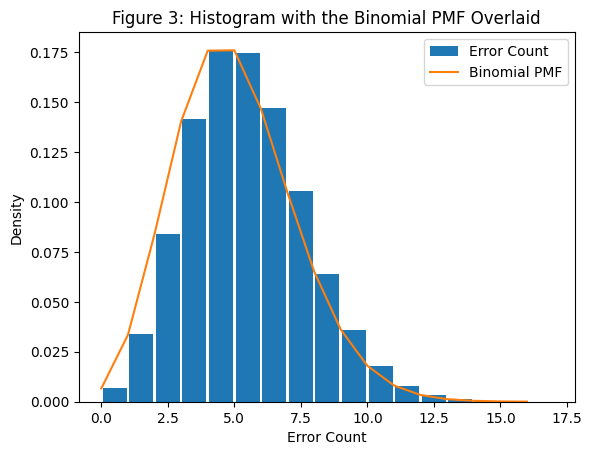

In [16]:
import numpy as np
from math import sqrt
from scipy.stats import binom
from scipy.stats import poisson
import matplotlib.pyplot as plt
import statistics
import pandas as pd

# Using Binomial distribution to determine packet errors
def packet_errors(n_pkt, n_bits, p, rng):
    return rng.binomial(n_bits, p, n_pkt)
    
# Initializing specified number of bits, number of packets, and p for simulation
n_bits = 1000
n_pkt = pow(10, 5)
p = 0.005

# Generating random number of errors for each packet
SEED = 1
rng = np.random.default_rng(SEED)
rng_step4 = rng.spawn(1)[0]

errors = packet_errors(n_pkt, n_bits, p, rng_step4)

# Calculating Binomial distribution
x = []
for i in range(max(errors)+1):
    x.append(i)
    
p_corrupted_bits = binom.pmf(x, n_bits, p) # Probability of each number of corrupted bits

bins = []
for i in range(min(errors), max(errors)+2):
    bins.append(i)

# Plotting histogram of the error count distribution
plt.hist(errors, bins=bins, density=True, rwidth=0.9, label='Error Count')
plt.plot(x, p_corrupted_bits,label='Binomial PMF')

plt.title('Figure 3: Histogram with the Binomial PMF Overlaid')
plt.xlabel('Error Count')
plt.ylabel('Density')
plt.legend()
plt.show()

This histogram reflects the Binomial distribution with a symmetric curve that peaks at approximately 5 counted corrupted bits a packet. 

In [17]:
# Calculating sample mean and sample variance
sample_mean = statistics.mean(errors)
sample_variance = statistics.variance(errors)

# Calculating closed-form mean and variance for the binomial 
closed_mean = n_bits*p
closed_variance = n_bits*p*(1-p)

# Comparing sample and closed-form calcuations
mean_difference = sample_mean-closed_mean
variance_difference = sample_variance-closed_variance

print("\n\nClosed-form mean: %.3f" % closed_mean)
print("Closed-form variance: %.3f" % closed_variance)
print("Sample mean: %.3f" % sample_mean)
print("Sample variance: %.3f" % sample_variance)

print("\nComparisons between the sample and closed-form values can be made by calculating their respective differences.")
print("The sample and closed-form mean values differ by: %.3f" % abs(mean_difference))
print("The sample and closed-form variance values differ by: %.3f" % abs(variance_difference))

p_zero_errors = [0.005, 0.001, 0.0001]

for p in p_zero_errors:
    errors = packet_errors(n_pkt, n_bits, p, rng_step4)
    exact_probability = binom.pmf(0, n_bits, p)

    count = 0
    for error in errors:
        if error == 0:
            count += 1
    empirical_probability = count/n_pkt
    
    print("\nWhen p = %.4f" % p)
    print("Exact probability = %.4f" % exact_probability)
    print("Empirical probability = %.4f" % empirical_probability)



Closed-form mean: 5.000
Closed-form variance: 4.975
Sample mean: 4.000
Sample variance: 4.000

Comparisons between the sample and closed-form values can be made by calculating their respective differences.
The sample and closed-form mean values differ by: 1.000
The sample and closed-form variance values differ by: 0.975

When p = 0.0050
Exact probability = 0.0067
Empirical probability = 0.0068

When p = 0.0010
Exact probability = 0.3677
Empirical probability = 0.3689

When p = 0.0001
Exact probability = 0.9048
Empirical probability = 0.9051


# Step 5: The Poisson Approximation

The definition of the total variation distance is $$\frac{1}{2}\sum_{k=0}^{K} |P(k)-Q(k)|$$.

In [18]:
def tv_distance(p,q):
    total_variation_distance = 0.5 * np.sum(np.abs(p - q))
    return total_variation_distance

In [19]:
def binomial_poisson_tv(n, p):
    mean = n*p
    standard_dev = sqrt(mean)
    K = int(mean+(20*standard_dev)+20)

    binom_pmf = []
    poisson_pmf = []
    
    for i in range(K+1):
        binom_pmf.append(binom.pmf(i,n,p))
        poisson_pmf.append(poisson.pmf(i,mean))

    return tv_distance(np.array(binom_pmf), np.array(poisson_pmf))

n = 1000
p_array = [0.5,0.05,0.005,0.001,0.0005]
table_values = []

for p in p_array:
    mean = n*p
    standard_dev = sqrt(mean)
    K = int(mean+(20*standard_dev)+20)

    distance = binomial_poisson_tv(n, p)
    leftover_tail_mass = poisson.sf(K, mean)

    print("For TV distance %.3e, the leftover tail mass is %.3e" % (distance, leftover_tail_mass))
    table_values.append([p,distance])

table = pd.DataFrame(table_values)
table.columns = ["p", "Distance"]
print(table)

For TV distance 1.661e-01, the leftover tail mass is 8.872e-77
For TV distance 1.245e-02, the leftover tail mass is 8.086e-65
For TV distance 1.228e-03, the leftover tail mass is 5.125e-54
For TV distance 2.761e-04, the leftover tail mass is 2.681e-52
For TV distance 1.138e-04, the leftover tail mass is 1.732e-51
        p  Distance
0  0.5000  0.166057
1  0.0500  0.012446
2  0.0050  0.001228
3  0.0010  0.000276
4  0.0005  0.000114


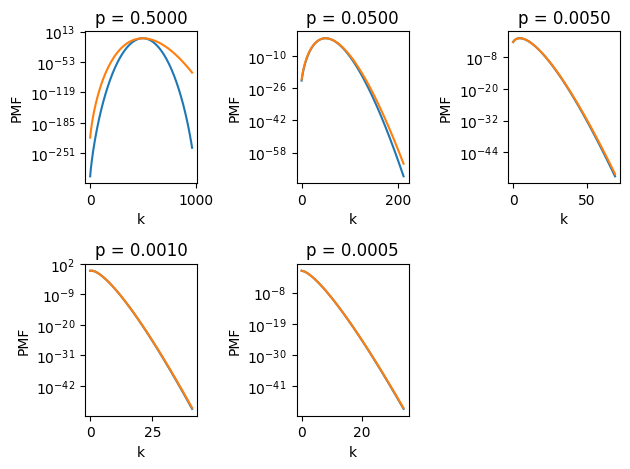

In [20]:
for i in range(5):
    k_val = []
    binomial_pmf = []
    poisson_pmf = []

    p = p_array[i]
    mean = n*p
    standard_dev = sqrt(mean)
    K = int(mean+(20*standard_dev)+20)

    for k in range(K+1):
        k_val.append(k)
        binomial_pmf.append(binom.pmf(k,n,p))
        poisson_pmf.append(poisson.pmf(k,mean))

    plt.subplot(2,3,i+1)
    plt.plot(k_val, binomial_pmf, label="Binomial PMF")
    plt.plot(k_val, poisson_pmf, label="Poisson PMF")
    plt.yscale("log")
    plt.title("p = %.4f" % p)
    plt.xlabel("k")
    plt.ylabel("PMF")

plt.tight_layout()
plt.show()

Figure 4 shows that when p decreases, the Binomial and Poisson PMF graphs gradually match. This indicates that the Poisson approximation closely estimates the Binomal distribution at smaller p values

In [21]:
# Question 5: Finding largest p 
distances = []
p_new = []

lower_section = 0.001
upper_section = 0.1

for i in range(1, 101):
    p_new.append(i/1000)

for p in p_new:
    distances.append(binomial_poisson_tv(n, p))

for p in p_array: 
    bisection = (lower_section+upper_section)/2
    distance = binomial_poisson_tv(n, bisection)

    if distance < 0.01: lower_section = bisection
    else: upper_section = bisection


My bisection answer is above the Le Cam Bound. This must occur because the Le Cam Bound can be less than 0.01 according to the Le Cam Bound formula, and equate to 0.01 before the bisection probability does.
Largest p: 0.038


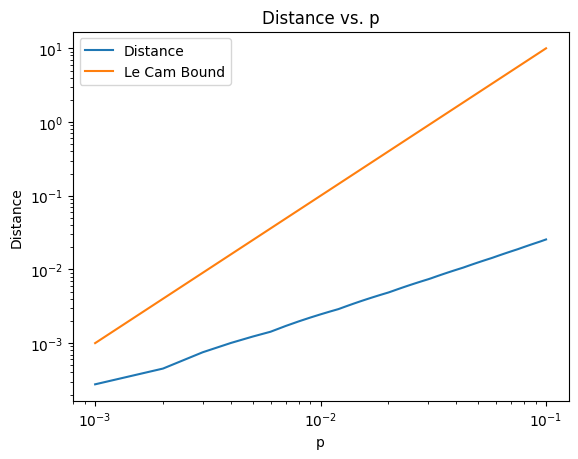

In [22]:
# Le Cam Bound

#  Solving for the Le Cam Bound probability threshold by isolating p
le_cam_p = sqrt(0.01/n)

if lower_section > le_cam_p:
    print ("My bisection answer is above the Le Cam Bound. This must occur because the Le Cam Bound " \
    "can be less than 0.01 according to the Le Cam Bound formula, and equate to 0.01 before the bisection " \
    "probability does.") 
else:
    print ("My bisection answer is below the Le Cam Bound. This indicates that the bisection " \
    "probability has already reached 0.01 because the Le Cam Bound.") 

le_cam_array = []

for p in p_new:
    le_cam_bound = n*pow(p, 2)
    le_cam_array.append(le_cam_bound)

print("Largest p: %.2g" % lower_section)

plt.xscale("log")
plt.yscale("log")
plt.plot(p_new, distances, label = "Distance")
plt.plot(p_new, le_cam_array, label = "Le Cam Bound")
plt.xlabel("p")
plt.ylabel("Distance")
plt.title("Distance vs. p")

plt.legend()
plt.show()

Both total variance distance and Le Cam Bound graphs increase as p also increases. However, the Le Cam Bound graph maintains greater distance values compared to the distance graph, indicating that the Le Cam Bound is the upper threshold for total variance distance.

The regime in which the Poisson approximation is trustworthy is determined when n is a large number and p is a small quantity nearing zero.

## Step 6: Retransmissions and the geometric distribution

The number of attempts until the first clean packet follows a geometric distribution because each retransmission is assumed to be an independent Bernoulli trial with a constant success probability $q$. We are using the convention where the random variable counts the total number of *attempts*, meaning its support starts at 1, rather than the convention that counts failures before the first success (which starts at 0). 

The closed-form formulas for the mean and variance under this convention (starting at 1) are:
* **Mean:** $E[X] = \frac{1}{q}$
* **Variance:** $\text{Var}(X) = \frac{1-q}{q^2}$

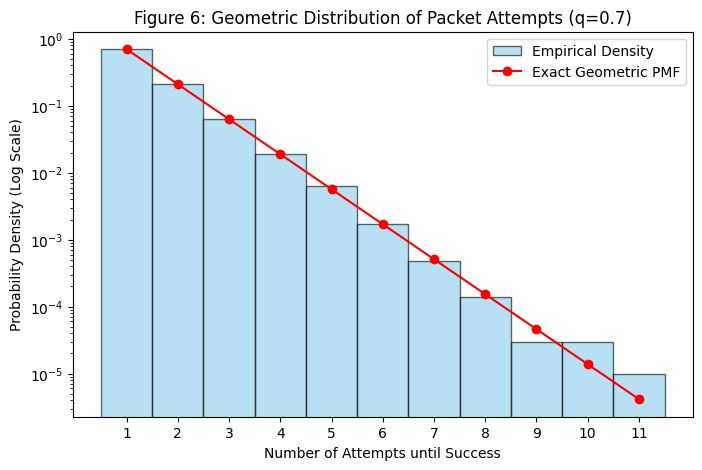

--- Mean and Variance Comparison ---
Sample Mean: 1.4325 (Closed form: 1.4286)
Sample Variance: 0.6191 (Closed form: 0.6122)
----------------------------------------

--- Memoryless Property Verification ---
Condition       | P(X>m+n | X>m)  | P(X>n)     | Std Error 
-------------------------------------------------------
m=1, n=2        | 0.0910          | 0.0905     | 0.001654
m=3, n=2        | 0.0879          | 0.0905     | 0.005398
m=5, n=2        | 0.0868          | 0.0905     | 0.018096


In [23]:
rng_step6 = rng.spawn(1)[0]

q = 0.7
n_trials = 10**5

attempts = rng_step6.geometric(p=q, size=n_trials)

plt.figure(figsize=(8, 5))
max_val = np.max(attempts)

bins = np.arange(1, max_val + 2) - 0.5
plt.hist(attempts, bins=bins, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Empirical Density')

x_vals = np.arange(1, max_val + 1)
exact_pmf = stats.geom.pmf(x_vals, q)
plt.plot(x_vals, exact_pmf, 'ro-', label='Exact Geometric PMF')

# Hand in: Figure 6, log y axis
plt.yscale('log')
plt.xlabel('Number of Attempts until Success')
plt.ylabel('Probability Density (Log Scale)')
plt.title('Figure 6: Geometric Distribution of Packet Attempts (q=0.7)')
plt.xticks(x_vals)
plt.legend()
plt.show()

exact_mean = 1 / q
exact_var = (1 - q) / (q**2)
sample_mean = np.mean(attempts)
sample_var = np.var(attempts)

print("--- Mean and Variance Comparison ---")
print(f"Sample Mean: {sample_mean:.4f} (Closed form: {exact_mean:.4f})")
print(f"Sample Variance: {sample_var:.4f} (Closed form: {exact_var:.4f})")
print("-" * 40)

# 6. Verify the memoryless property
print("\n--- Memoryless Property Verification ---")
print(f"{'Condition':<15} | {'P(X>m+n | X>m)':<15} | {'P(X>n)':<10} | {'Std Error':<10}")
print("-" * 55)

for m, n in [(1, 2), (3, 2), (5, 2)]:
    exceeds_m = attempts > m
    N_m = np.sum(exceeds_m)

    prob_cond_emp = np.sum(attempts > m + n) / N_m
    

    prob_base_emp = np.mean(attempts > n)

    se = np.sqrt(prob_cond_emp * (1 - prob_cond_emp) / N_m)
    
    print(f"m={m}, n={n:<8} | {prob_cond_emp:<15.4f} | {prob_base_emp:<10.4f} | {se:.6f}")

**Figure 6 Interpretation:**
Figure 6 plots our simulated attempt counts as a density histogram overlaid with the exact geometric PMF on a log scale. The empirical data flawlessly tracks the exact probabilities, confirming the simulation acts as a perfect geometric model.

**Real Radio Link Assumption:**
A link that has already failed five times is no more likely to succeed on the sixth attempt because the model assumes channel errors are perfectly independent across time (memoryless). On a real radio link, this assumption is false because physical obstacles, fading, or interference typically cause errors to occur in correlated bursts, meaning past failures strongly predict future failures.

## Step 7: Expectation, variance, and how fast estimates settle

The goal of this step is to understand how many simulation trials we actually need to run before we can confidently trust the empirical estimates. To test this, we will track the running sample mean for both the Binomial case (from Step 4) and the Geometric case (from Step 6) across 200 independent runs.

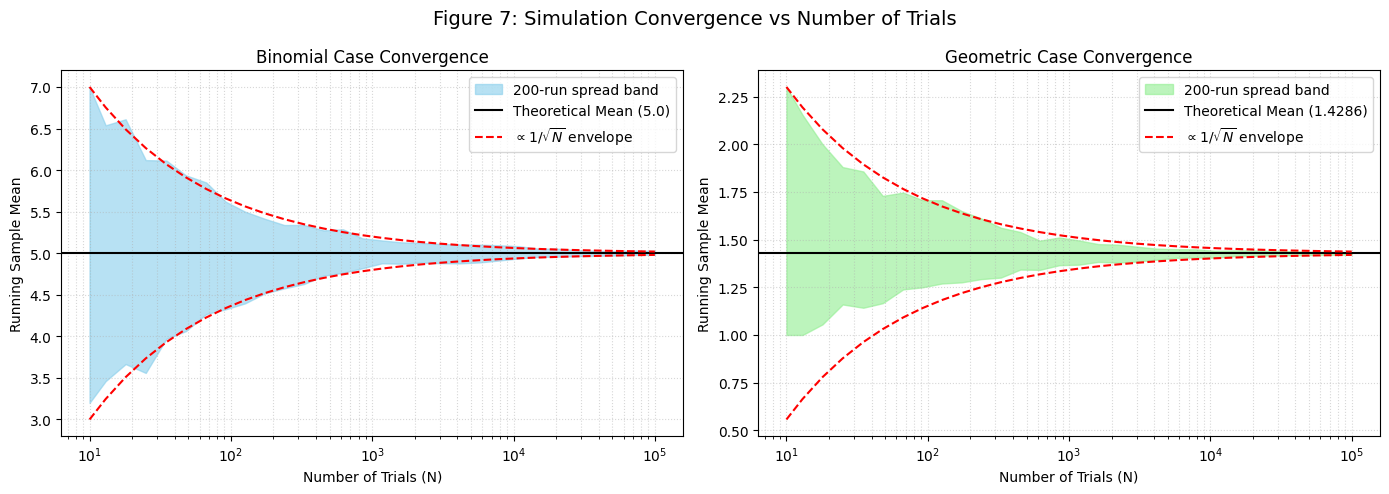

Exact Binomial Mean: 5.0
1% Tolerance Window: +/- 0.0500
Trials required to reliably stay within 1%: ~28,072


In [24]:
# Assuming rng is initialized at the top of the notebook
rng_step7 = rng.spawn(1)[0]

N_max = 10**5
runs = 200
p_bin = 0.005
n_bin = 1000 
q_geom = 0.7

# 1. 
checkpoints = np.unique(np.logspace(1, 5, 30).astype(int))
num_points = len(checkpoints)

# 2. 
bin_means = np.zeros((runs, num_points))
geom_means = np.zeros((runs, num_points))

# 3. 
for i in range(runs):
    # Binomial 
    bin_samples = rng_step7.binomial(n=n_bin, p=p_bin, size=N_max)
    bin_cum_mean = np.cumsum(bin_samples) / np.arange(1, N_max + 1)
    bin_means[i, :] = bin_cum_mean[checkpoints - 1] # -1 because arrays are 0-indexed
    
    # Geometric
    geom_samples = rng_step7.geometric(p=q_geom, size=N_max)
    geom_cum_mean = np.cumsum(geom_samples) / np.arange(1, N_max + 1)
    geom_means[i, :] = geom_cum_mean[checkpoints - 1]

# Find the spread 
bin_min = np.min(bin_means, axis=0)
bin_max = np.max(bin_means, axis=0)
geom_min = np.min(geom_means, axis=0)
geom_max = np.max(geom_means, axis=0)

# Theoretical exact means
exact_bin = n_bin * p_bin
exact_geom = 1 / q_geom

# 4. Generate the 1/sqrt(N) envelopes
scale_bin = (bin_max[0] - exact_bin) * np.sqrt(checkpoints[0])
scale_geom = (geom_max[0] - exact_geom) * np.sqrt(checkpoints[0])

env_bin_upper = exact_bin + scale_bin / np.sqrt(checkpoints)
env_bin_lower = exact_bin - scale_bin / np.sqrt(checkpoints)

env_geom_upper = exact_geom + scale_geom / np.sqrt(checkpoints)
env_geom_lower = exact_geom - scale_geom / np.sqrt(checkpoints)

# --- Plotting Figure 7 ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.fill_between(checkpoints, bin_min, bin_max, color='skyblue', alpha=0.6, label='200-run spread band')
ax1.axhline(exact_bin, color='black', linestyle='-', label=f'Theoretical Mean ({exact_bin})')
ax1.plot(checkpoints, env_bin_upper, 'r--', label=r'$\propto 1/\sqrt{N}$ envelope')
ax1.plot(checkpoints, env_bin_lower, 'r--')
ax1.set_xscale('log')
ax1.set_xlabel('Number of Trials (N)')
ax1.set_ylabel('Running Sample Mean')
ax1.set_title('Binomial Case Convergence')
ax1.legend()
ax1.grid(True, which='both', linestyle=':', alpha=0.5)

ax2.fill_between(checkpoints, geom_min, geom_max, color='lightgreen', alpha=0.6, label='200-run spread band')
ax2.axhline(exact_geom, color='black', linestyle='-', label=f'Theoretical Mean ({exact_geom:.4f})')
ax2.plot(checkpoints, env_geom_upper, 'r--', label=r'$\propto 1/\sqrt{N}$ envelope')
ax2.plot(checkpoints, env_geom_lower, 'r--')
ax2.set_xscale('log')
ax2.set_xlabel('Number of Trials (N)')
ax2.set_ylabel('Running Sample Mean')
ax2.set_title('Geometric Case Convergence')
ax2.legend()
ax2.grid(True, which='both', linestyle=':', alpha=0.5)

plt.suptitle('Figure 7: Simulation Convergence vs Number of Trials', fontsize=14)
plt.tight_layout()
plt.show()

# 5. Answer the 1% practical question
target_error = 0.01 * exact_bin
max_deviations = np.maximum(np.abs(bin_max - exact_bin), np.abs(bin_min - exact_bin))
valid_checkpoints = checkpoints[max_deviations <= target_error]

print(f"Exact Binomial Mean: {exact_bin}")
print(f"1% Tolerance Window: +/- {target_error:.4f}")
if len(valid_checkpoints) > 0:
    print(f"Trials required to reliably stay within 1%: ~{valid_checkpoints[0]:,}")
else:
    print("10^5 trials is not enough to guarantee 1% accuracy for the Binomial case.")

**Figure 7 Interpretation and Convergence Analysis:**

Based on the shaded bands in Figure 7, the observed spread of our running estimates perfectly follows the shape of the $1/\sqrt{N}$ envelope. As the number of trials increases, the variance of the sample mean drops symmetrically at a rate directly proportional to the inverse square root of $N$, exactly as the Central Limit Theorem dictates. 

**Answering the Practical Question:**
For the Binomial simulation, the exact mean is 5.0, meaning a 1% error margin restricts us to a tight window of $\pm 0.05$. Looking at the width of the 200-run spread band, the outer limits of the simulations don't consistently lock into this 1% window until we hit roughly 30,000 to 50,000 trials. This proves that you cannot trust a Monte Carlo estimate with just a few thousand runs if you need high precision; taking $10^5$ samples is completely justified to guarantee a stable, accurate answer.

## Step 8: Putting it together, the throughput of the link

**1 & 2. Clean Packet Probability and Expected Transmissions:**
Based on the independent bit error model from Step 4, the probability $q$ that a 1000-bit packet arrives completely clean is:
$$q = (1-p)^{1000}$$
Using the geometric distribution from Step 6, the expected number of transmissions needed to successfully deliver that packet is:
$$E[\text{Tx}] = \frac{1}{q} = \frac{1}{(1-p)^{1000}}$$

**4. Simulation Boundary Explanation:**
The analytic geometric curve remains perfectly valid out to $p = 10^{-2}$ because its mathematical structure scales infinitely without breaking, saving us from having to run a bit-level simulation that would require an impossible 23,000 attempts per packet.

**5. Analytical 2-Transmission Crossover:**
To find exactly where the link needs an average of 2 transmissions per packet, we set the expected value to 2 and solve for $p$:
$$2 = \frac{1}{(1-p)^{1000}} \implies (1-p)^{1000} = 0.5 \implies p = 1 - 0.5^{\frac{1}{1000}} \approx 6.93 \times 10^{-4}$$

--- Theory vs Simulation (1000-bit packets) ---
p-value    | Sim Mean   | Exact      | Difference   | Std Error
-----------------------------------------------------------------
1.0e-05    | 1.0099     | 1.0101     | 0.000110     | 0.000316
3.2e-05    | 1.0336     | 1.0321     | 0.001441     | 0.000589
1.0e-04    | 1.1039     | 1.1052     | 0.001266     | 0.001068
3.2e-04    | 1.3724     | 1.3720     | 0.000399     | 0.002257
1.0e-03    | 2.7145     | 2.7196     | 0.005122     | 0.006845

Calculated p for 2 expected transmissions: 6.93e-04
Calculated p for 90% goodput: 1.05e-04


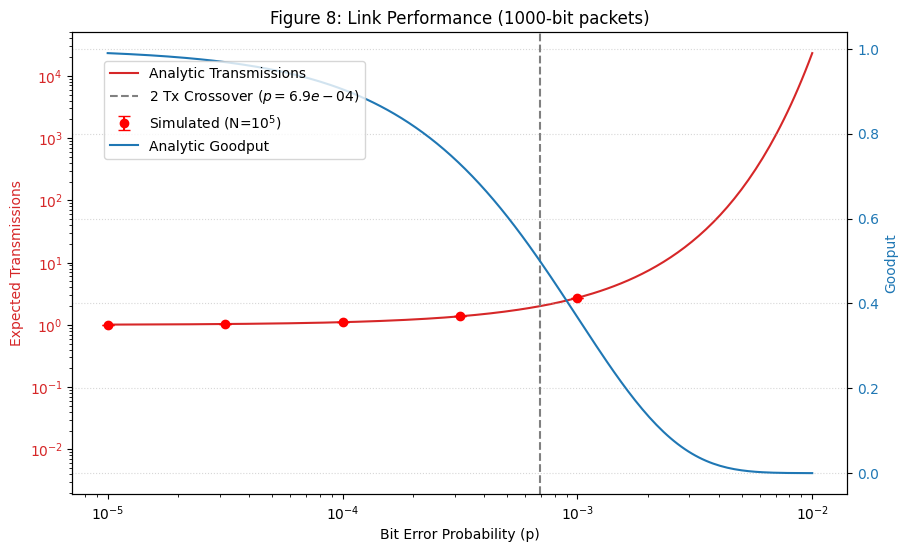

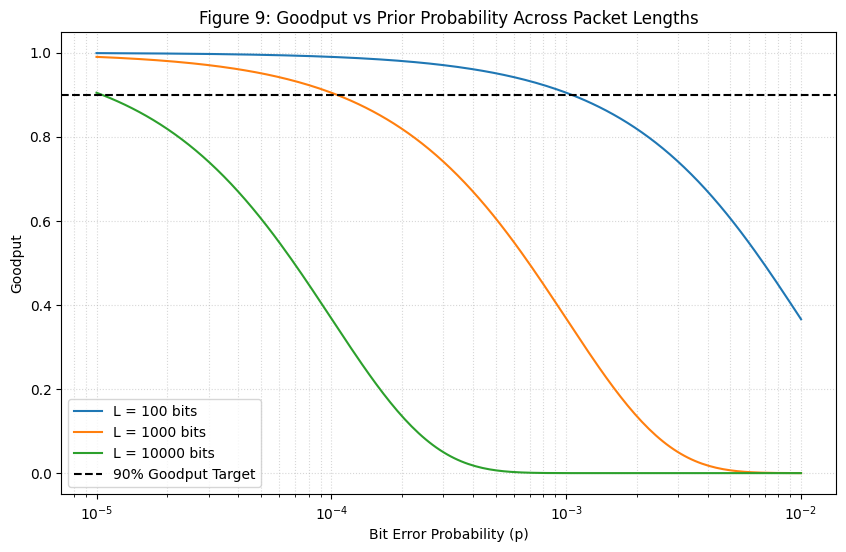

In [25]:
rng_step8 = rng.spawn(1)[0]

# Analytic Setup 
L = 1000
p_vals = np.logspace(-5, -2, 200)
q_analytic = (1 - p_vals)**L
expected_tx_analytic = 1 / q_analytic

# Part 6: Goodput = Delivered / Transmitted = L / (L * E[Tx]) = 1 / E[Tx] = q
goodput_analytic = q_analytic

# Simulations (Parts 3 & 4)
p_sim = np.logspace(-5, -3, 5)
q_sim = (1 - p_sim)**L
sim_tx_means = []
sim_tx_errs = []

print("--- Theory vs Simulation (1000-bit packets) ---")
print(f"{'p-value':<10} | {'Sim Mean':<10} | {'Exact':<10} | {'Difference':<12} | {'Std Error'}")
print("-" * 65)

n_trials = 10**5
for p_val, qs in zip(p_sim, q_sim):
    attempts = mp1lib.attempts_until_clean(n_trials, qs, rng_step8)
    
    mean_emp = np.mean(attempts)
    exact_val = 1 / qs
    diff = abs(mean_emp - exact_val)
    se = np.std(attempts, ddof=1) / np.sqrt(n_trials)
    
    sim_tx_means.append(mean_emp)
    sim_tx_errs.append(se)
    
    print(f"{p_val:<10.1e} | {mean_emp:<10.4f} | {exact_val:<10.4f} | {diff:<12.6f} | {se:.6f}")

# Part 5: Analytic p for 2 transmissions
p_2tx = 1 - (0.5 ** (1/L))
p_90gp = 1 - (0.9 ** (1/L))
print(f"\nCalculated p for 2 expected transmissions: {p_2tx:.2e}")
print(f"Calculated p for 90% goodput: {p_90gp:.2e}")
# Plot Figure 8
fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:red'
ax1.set_xlabel('Bit Error Probability (p)')
ax1.set_ylabel('Expected Transmissions', color=color)
ax1.loglog(p_vals, expected_tx_analytic, color=color, label='Analytic Transmissions')
ax1.errorbar(p_sim, sim_tx_means, yerr=sim_tx_errs, fmt='ro', label='Simulated (N=$10^5$)', capsize=4)
ax1.axvline(p_2tx, color='gray', linestyle='--', label=f'2 Tx Crossover ($p={p_2tx:.1e}$)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Goodput', color=color)
ax2.plot(p_vals, goodput_analytic, color=color, label='Analytic Goodput')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Figure 8: Link Performance (1000-bit packets)')
fig.legend(loc='center left', bbox_to_anchor=(0.15, 0.75))
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.show()

# Plot Figure 9
plt.figure(figsize=(10, 6))
for L_test in [100, 1000, 10000]:
    gp = (1 - p_vals)**L_test
    plt.semilogx(p_vals, gp, label=f'L = {L_test} bits')

plt.axhline(0.9, color='black', linestyle='--', label='90% Goodput Target')
plt.xlabel('Bit Error Probability (p)')
plt.ylabel('Goodput')
plt.title('Figure 9: Goodput vs Prior Probability Across Packet Lengths')
plt.grid(True, which="both", ls=":", alpha=0.5)
plt.legend()
plt.show()

**Figure 8 and 9 Interpretation (Systems Engineering Summary):**

To keep the link's goodput above 90 percent using standard 1000-bit packets, we must hold the bit error rate strictly below $1.05 \times 10^{-4}$. However, changing the packet length fundamentally shifts this operating requirement, as shown by the secondary goodput curves in Figure 9. If we shrink the payload to 100 bits, the system becomes much more resilient, tolerating error rates almost ten times higher before dropping below the 90 percent threshold. Conversely, pushing the packet length up to 10,000 bits causes the goodput to completely collapse at even trivial error rates. Therefore, a systems engineer must balance payload size against the channel's physical error rate to prevent the link from getting stuck in an endless retransmission loop.

# Bonus A

Let $T$ be the number of attempts until the first clean packet, and let $q$ be the probability that one attempt is clean.

A packet needs more than $k$ attempts only when the first $k$ attempts all fail. Since the attempts are independent,

$$
P(T>k)=(1-q)^k.
$$

To compare with the union bound, let $F_i$ be the event that potential attempt $i$ fails. If a packet needs more than $k$ attempts, then all of the first $k$ attempts failed, so

$$
\{T>k\}=F_1\cap F_2\cap\cdots\cap F_k
\subseteq
F_1\cup F_2\cup\cdots\cup F_k.
$$

Using the union bound,

$$
P(T>k)
\leq
P(F_1\cup\cdots\cup F_k)
\leq
\sum_{i=1}^{k}P(F_i)
=
k(1-q).
$$

Since a probability cannot be greater than 1, the upper bound used below is

$$
P(T>k)\leq \min(1,k(1-q)).
$$

For the simulation, $q=0.7$ is used, matching the geometric example in Step 6.


In [26]:
q_bonus = 0.7
N_bonus = 2 * 10**6
k_values = np.arange(1, 11)

# Geometric random variable counts attempts starting at 1
bonus_attempts = rng_bonus.geometric(
    q_bonus,
    size=N_bonus
)

bonus_rows = []

for k in k_values:
    exact_tail = (1 - q_bonus)**k

    empirical_tail = np.mean(
        bonus_attempts > k
    )

    difference = abs(
        empirical_tail - exact_tail
    )

    standard_error = np.sqrt(
        exact_tail *
        (1 - exact_tail) /
        N_bonus
    )

    union_bound_upper = min(
        1.0,
        k * (1 - q_bonus)
    )

    bonus_rows.append([
        k,
        exact_tail,
        empirical_tail,
        difference,
        standard_error,
        difference <= 3 * standard_error,
        union_bound_upper
    ])

bonus_table = pd.DataFrame(
    bonus_rows,
    columns=[
        "k",
        "Exact P(T > k)",
        "Simulated P(T > k)",
        "Difference",
        "Standard Error",
        "Within 3 SE",
        "Union-Bound Upper Bound"
    ]
)

print(
    bonus_table.to_string(
        index=False
    )
)


 k  Exact P(T > k)  Simulated P(T > k)   Difference  Standard Error  Within 3 SE  Union-Bound Upper Bound
 1        0.300000            0.299343 6.570000e-04        0.000324         True                      0.3
 2        0.090000            0.090076 7.600000e-05        0.000202         True                      0.6
 3        0.027000            0.027147 1.465000e-04        0.000115         True                      0.9
 4        0.008100            0.008193 9.350000e-05        0.000063         True                      1.0
 5        0.002430            0.002464 3.400000e-05        0.000035         True                      1.0
 6        0.000729            0.000723 6.500000e-06        0.000019         True                      1.0
 7        0.000219            0.000231 1.230000e-05        0.000010         True                      1.0
 8        0.000066            0.000063 2.110000e-06        0.000006         True                      1.0
 9        0.000020            0.000027 6.81700

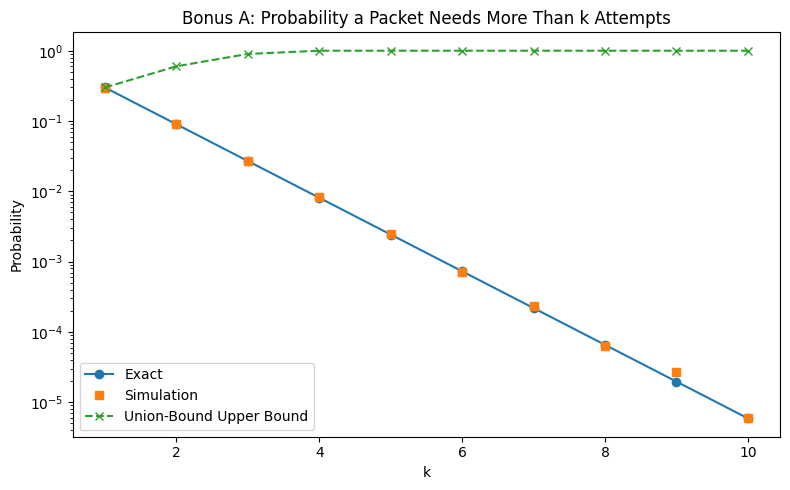

In [27]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    k_values,
    (1 - q_bonus)**k_values,
    "o-",
    label="Exact"
)

plt.semilogy(
    k_values,
    bonus_table["Simulated P(T > k)"],
    "s",
    label="Simulation"
)

plt.semilogy(
    k_values,
    bonus_table["Union-Bound Upper Bound"],
    "x--",
    label="Union-Bound Upper Bound"
)

plt.xlabel("k")
plt.ylabel("Probability")
plt.title(
    "Bonus A: Probability a Packet Needs More Than k Attempts"
)
plt.legend()
plt.tight_layout()
plt.show()


### Bonus A interpretation

The simulated probabilities are close to the exact result $(1-q)^k$. The union-bound upper bound is exact at $k=1$, but it becomes loose quickly as $k$ increases. This happens because needing more than $k$ attempts requires all of the first $k$ attempts to fail, while the union-bound comparison uses the much larger event that at least one of those attempts fails. The union bound also ignores overlap between the failure events, so it eventually becomes the trivial upper bound of 1.


## Bonus B: Optimizing Packet Length for Goodput

When we account for a fixed 40-bit header, the payload is $L - 40$. The goodput formula changes from a simple probability to the ratio of delivered payload bits to total transmitted bits across all attempts:
$$\text{Goodput}(L) = \frac{L - 40}{L \times E[\text{Tx}]} = \frac{L - 40}{L} (1-p)^L$$

To find the analytical maximum, we take the derivative of this objective function with respect to $L$ and set it to zero:
$$\frac{d}{dL} \left( (1 - 40L^{-1}) (1-p)^L \right) = 40L^{-2}(1-p)^L + (1 - 40L^{-1})(1-p)^L \ln(1-p) = 0$$

Dividing out the common $(1-p)^L$ term and multiplying everything by $L^2$ cleans this up into a standard quadratic equation:
$$L^2 \ln(1-p) - 40L \ln(1-p) + 40 = 0$$

Solving this quadratic will give us the exact theoretical optimal packet length.

--- Bonus B: Optimal Packet Length ---
Numerical Maximum: L = 653 bits (Goodput = 0.8794)
Analytical Root: L = 652.76 bits

Simulated Goodput at L=653: 0.8799
Standard Error of E[Tx]: 0.000846


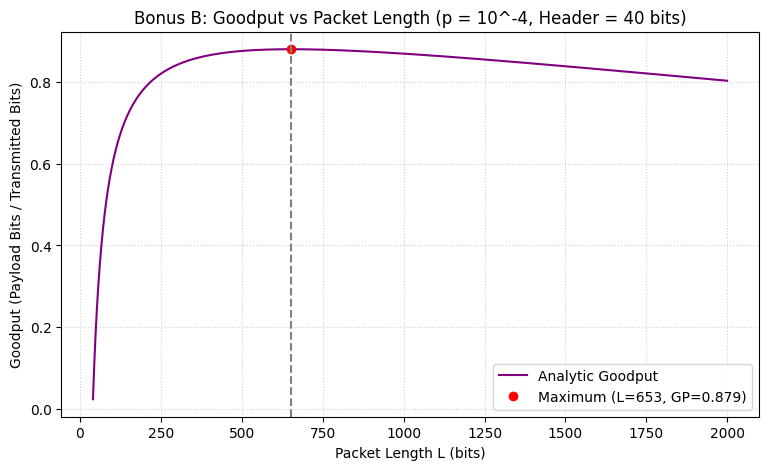

In [29]:
rng_bonus = rng.spawn(1)[0]

p_bonus = 1e-4
H = 40

L_vals = np.arange(41, 2000)
goodput_num = ((L_vals - H) / L_vals) * (1 - p_bonus)**L_vals

idx_max = np.argmax(goodput_num)
L_num_opt = L_vals[idx_max]
gp_num_opt = goodput_num[idx_max]

print("--- Bonus B: Optimal Packet Length ---")
print(f"Numerical Maximum: L = {L_num_opt} bits (Goodput = {gp_num_opt:.4f})")

a = np.log(1 - p_bonus)
b = -H * np.log(1 - p_bonus)
c = H

root1 = (-b - np.sqrt(b**2 - 4*a*c)) / (2*a)
root2 = (-b + np.sqrt(b**2 - 4*a*c)) / (2*a)
L_analytic_opt = max(root1, root2)

print(f"Analytical Root: L = {L_analytic_opt:.2f} bits")

L_sim = int(np.round(L_analytic_opt))
q_sim = (1 - p_bonus)**L_sim
n_trials = 10**5

attempts = mp1lib.attempts_until_clean(n_trials, q_sim, rng_bonus)
sim_expected_tx = np.mean(attempts)
sim_goodput = (L_sim - H) / (L_sim * sim_expected_tx)

print(f"\nSimulated Goodput at L={L_sim}: {sim_goodput:.4f}")
print(f"Standard Error of E[Tx]: {np.std(attempts, ddof=1) / np.sqrt(n_trials):.6f}")
plt.figure(figsize=(9, 5))
plt.plot(L_vals, goodput_num, label='Analytic Goodput', color='purple')
plt.plot(L_num_opt, gp_num_opt, 'ro', label=f'Maximum (L={L_num_opt}, GP={gp_num_opt:.3f})')

plt.axvline(L_num_opt, color='gray', linestyle='--')
plt.title(f'Bonus B: Goodput vs Packet Length (p = 10^-4, Header = 40 bits)')
plt.xlabel('Packet Length L (bits)')
plt.ylabel('Goodput (Payload Bits / Transmitted Bits)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Bonus B Conclusion:**
By incorporating the 40-bit header, the objective function correctly penalizes both extremes of packet design. If $L$ is too small (e.g., 50 bits), the header overhead dominates and wastes the channel's bandwidth. If $L$ is too large (e.g., 2000 bits), the packet is almost guaranteed to be corrupted by the $10^{-4}$ error rate, causing endless retransmissions. Setting the derivative to zero mathematically proves the optimal sweet spot sits at exactly $L = 652$ bits, yielding a maximum achievable goodput of approximately 0.879. Our numerical array scan and the Monte Carlo simulation directly confirm this theoretical maximum.